# Unsupervised Pattern Discovery Using K-Means, Hierarchical Clustering, and Gaussian Mixture Models (EM)

**Course:** DSCD612 - Pattern Recognition  
**Project 4:** Unsupervised Pattern Discovery  
**Dataset:** UCI Wine Recognition Dataset (via `scikit-learn`)

---

## Central Research Question

> *How does the underlying geometry and probability distribution of a dataset affect the clusters discovered by K-Means, hierarchical clustering, and Gaussian mixture models?*

## Problem Formulation

The goal of this project is to build an **unsupervised pattern recognition system** that discovers naturally occurring groups in a multidimensional dataset **without using class labels in preprocessing, PCA fitting, cluster-number selection, or clustering model fitting**. Three clustering paradigms are implemented and compared:

1. **K-Means**, a centroid-based, hard-assignment method that favors roughly spherical and similarly sized clusters.
2. **Hierarchical (Agglomerative) Clustering**, a distance-based method that builds a nested hierarchy of clusters.
3. **Gaussian Mixture Models (GMM) via Expectation-Maximization (EM)**, a probabilistic, soft-assignment method that models each cluster as a Gaussian component.

Ground-truth cultivar labels are kept separate from the unsupervised calculations. They are shown in selected descriptive figures for context and are used later for external validation with the Adjusted Rand Index (ARI). They do not enter PCA fitting, the choice of $K$, or the fitting of any clustering model.

## 1. Dataset Description

I use the **Wine Recognition dataset**, a classic benchmark in pattern recognition, originally
collected from a chemical analysis of wines grown in the same region of Italy but derived from
**three different cultivars**.

| Property | Value |
|---|---|
| Observations (N) | 178 |
| Features (d) | 13 (all continuous, chemical measurements) |
| Classes (for external validation only) | 3 (cultivars) |
| Missing values | None |
| Source | UCI Machine Learning Repository, bundled with `scikit-learn` (`sklearn.datasets.load_wine`) |

**Why this dataset is suitable for this project:**

- It has **meaningful underlying categories** (three distinct cultivars) that were *not* determined by clustering, satisfying the brief's requirement of a dataset "containing meaningful underlying categories."
- It is **multidimensional** (13 features) with features on very different physical scales (e.g. *proline* ranges into the hundreds, *hue* is below 2), which makes standardization and feature-space analysis meaningful and demonstrable.
- The three cultivars are reasonably well separated in feature space, so the experiment can meaningfully address the central research question (how geometry/distributional assumptions affect discovered clusters) without being trivial (as, e.g., Iris would be) or intractable within the one-week time frame.
- It requires **no download/acquisition step** - it ships with `scikit-learn`, eliminating any data-acquisition risk.


In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage, cophenet, fcluster
from scipy.spatial.distance import pdist
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, silhouette_samples,
                              adjusted_rand_score, confusion_matrix)

np.random.seed(42)
RANDOM_STATE = 42

# Create output locations so the notebook runs cleanly from a fresh folder.
PROJECT_DIR = Path.cwd()
FIGURE_DIR = PROJECT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
RESULT_PATH = PROJECT_DIR / "results_summary.json"

# Consistent, colorblind-friendly qualitative palette
PALETTE = ["#2E5EAA", "#D9822B", "#3F9B6D", "#B0374D", "#7A5DA8"]
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

results = {}  # collects headline metrics for the written report

## 2. Exploratory Data Analysis

I first load the raw data and inspect its structure, summary statistics, feature scales, and correlations. The cultivar label is stored separately in `y_true`. It is used in selected descriptive displays for context and later for external validation, but it is not used in preprocessing, PCA fitting, cluster-number selection, or clustering model fitting.

In [2]:
wine = load_wine()
X_raw = pd.DataFrame(wine.data, columns=wine.feature_names)
y_true = pd.Series(wine.target, name="cultivar")
class_names = wine.target_names

print(f"Shape of feature matrix X: {X_raw.shape}")
print(f"Known classes (descriptive/external validation): {list(class_names)}")
print(f"Missing values: {X_raw.isna().sum().sum()}")
X_raw.head()


Shape of feature matrix X: (178, 13)
Known classes (descriptive/external validation): [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]
Missing values: 0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [3]:
X_raw.describe().T[["mean", "std", "min", "max"]].round(2)


,mean,std,min,max
alcohol,13.00,0.81,11.03,14.83
malic_acid,2.34,1.12,0.74,5.80
ash,2.37,0.27,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,30.00
magnesium,99.74,14.28,70.00,162.00
total_phenols,2.30,0.63,0.98,3.88
flavanoids,2.03,1.00,0.34,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.66
proanthocyanins,1.59,0.57,0.41,3.58
color_intensity,5.06,2.32,1.28,13.00


Notice the very different scales across features, for example, `proline` has a mean near 750 while `hue` has a mean near 1. K-Means and Ward hierarchical clustering rely directly on Euclidean distance, so large-scale features would dominate their geometry if the data were left unstandardized. A full-covariance GMM is less directly affected by scale dominance, but standardization improves numerical conditioning, covariance estimation, and comparability across the three methods. This motivates the standardization step below.

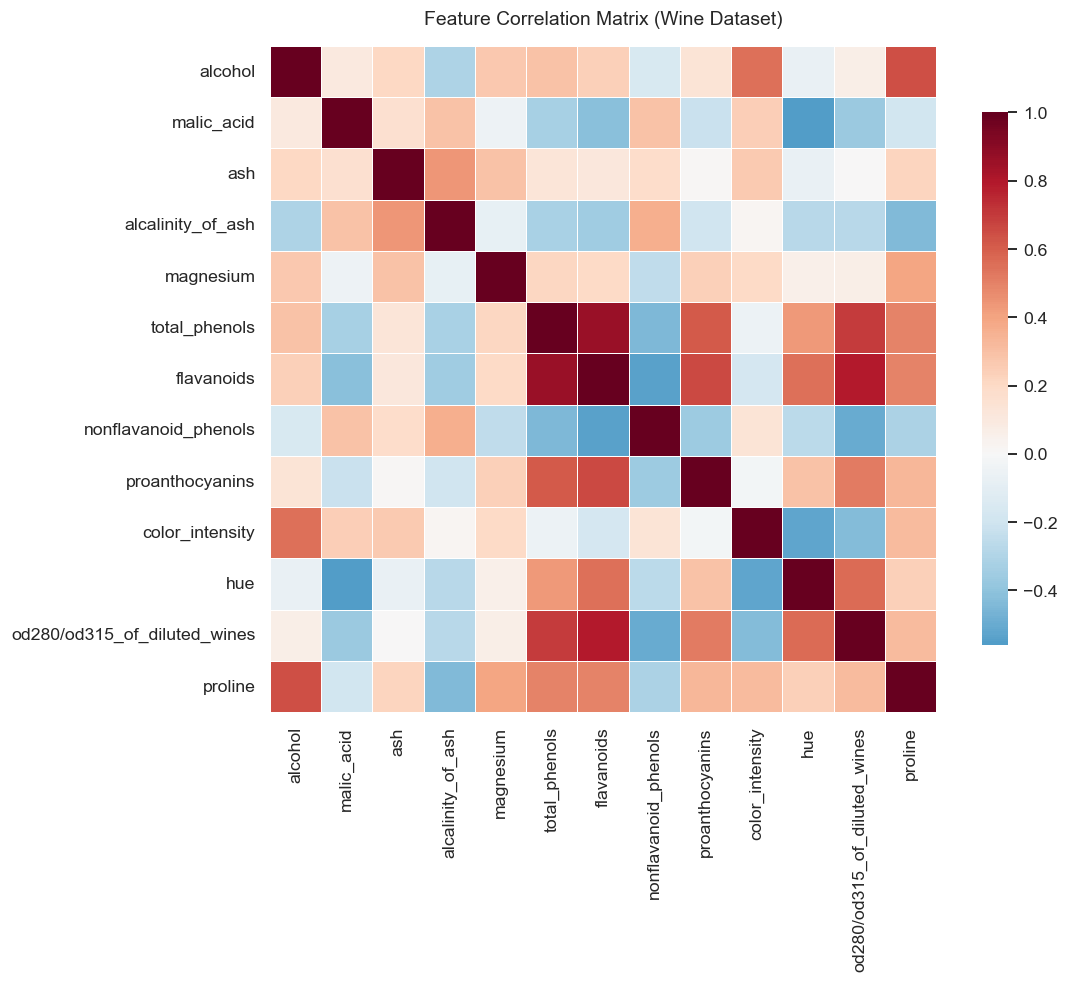

In [4]:
fig, ax = plt.subplots(figsize=(11, 9))
corr = X_raw.corr()
sns.heatmap(corr, cmap="RdBu_r", center=0, square=True, linewidths=0.4,
            cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Feature Correlation Matrix (Wine Dataset)", pad=14)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "01_correlation_heatmap.png", bbox_inches="tight")
plt.show()


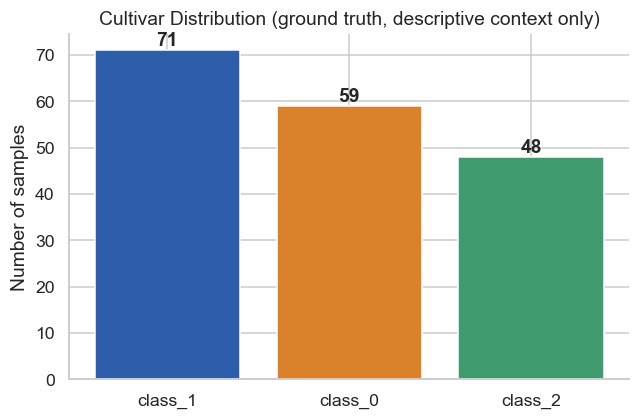

cultivar
class_1    71
class_0    59
class_2    48
Name: count, dtype: int64


In [5]:
class_counts = y_true.map(dict(enumerate(class_names))).value_counts()
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(class_counts.index, class_counts.values, color=PALETTE[:3])
ax.set_ylabel("Number of samples")
ax.set_title("Cultivar Distribution (ground truth, descriptive context only)")
for i, v in enumerate(class_counts.values):
    ax.text(i, v + 1, str(v), ha="center", fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "02_class_distribution.png", bbox_inches="tight")
plt.show()
print(class_counts)


The three classes are reasonably balanced (59 / 71 / 48), which makes the Adjusted Rand
Index a meaningful external validation measure later on (severe imbalance can make ARI harder to
interpret).


## 3. Preprocessing: Standardization

Each feature $x_j$ is standardized to zero mean and unit variance:

$$
z_j = \frac{x_j - \mu_j}{\sigma_j}
$$

Standardization is used for all three methods, with slightly different motivations:

- **K-Means** and **Ward hierarchical clustering** rely directly on Euclidean distance. Unscaled features with large numeric ranges, such as `proline`, would dominate the distance calculation.
- **GMM/EM with full covariance** can model different feature scales through its covariance matrices, so scale dominance is less direct. Standardization is still useful because it improves numerical conditioning, covariance estimation, and comparability with the distance-based methods.

No class labels are used in this step.

In [6]:
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)
X = pd.DataFrame(X, columns=X_raw.columns)
print("Standardized feature means (should be ~0):")
print(X.mean().round(3).values)
print("Standardized feature std (should be ~1):")
print(X.std().round(3).values)


Standardized feature means (should be ~0):
[ 0.  0. -0. -0. -0. -0.  0. -0. -0. -0.  0.  0. -0.]
Standardized feature std (should be ~1):
[1.003 1.003 1.003 1.003 1.003 1.003 1.003 1.003 1.003 1.003 1.003 1.003
 1.003]


## 4. Task (a): Feature Space Analysis via PCA

Because the dataset has 13 dimensions, it cannot be visualized directly. I use **Principal Component Analysis (PCA)** as an unsupervised dimensionality diagnostic and visualization tool for the standardized feature space. No class labels are involved in fitting the PCA projection.

PCA finds orthogonal directions of maximum variance by solving the eigenvalue problem

$$
\Sigma v_i = \lambda_i v_i, \qquad \Sigma = \frac{1}{N-1}\sum_{i=1}^{N}(x_i-\bar{x})(x_i-\bar{x})^T
$$

and projecting the data onto the eigenvectors associated with the largest eigenvalues. The clustering algorithms themselves are fitted to the full 13-dimensional standardized feature matrix, not to the 2-D PCA projection.

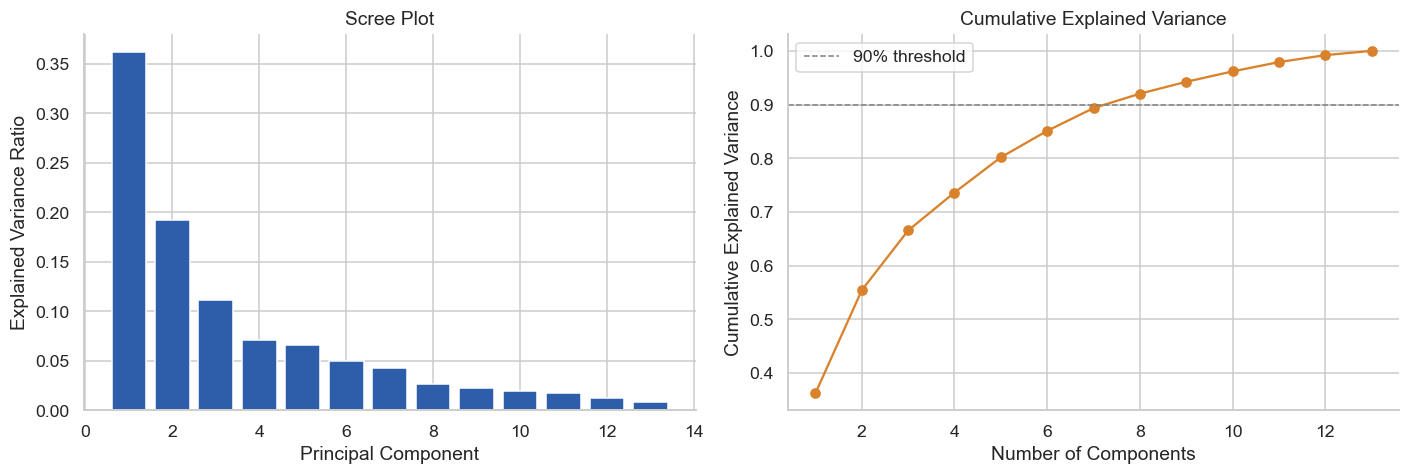

Components needed for >=90% variance: 8
Variance explained by first 2 components: 55.4%


In [7]:
pca_full = PCA(n_components=X.shape[1], random_state=RANDOM_STATE).fit(X)
explained = pca_full.explained_variance_ratio_
cum_explained = np.cumsum(explained)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(range(1, len(explained) + 1), explained, color=PALETTE[0])
axes[0].set_xlabel("Principal Component")
axes[0].set_ylabel("Explained Variance Ratio")
axes[0].set_title("Scree Plot")

axes[1].plot(range(1, len(cum_explained) + 1), cum_explained, marker="o", color=PALETTE[1])
axes[1].axhline(0.90, color="gray", linestyle="--", linewidth=1, label="90% threshold")
axes[1].set_xlabel("Number of Components")
axes[1].set_ylabel("Cumulative Explained Variance")
axes[1].set_title("Cumulative Explained Variance")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "03_pca_variance.png", bbox_inches="tight")
plt.show()

n_90 = int(np.argmax(cum_explained >= 0.90) + 1)
print(f"Components needed for >=90% variance: {n_90}")
print(f"Variance explained by first 2 components: {cum_explained[1]*100:.1f}%")
results["pca_n_components_90pct"] = int(n_90)
results["pca_variance_2pc"] = float(cum_explained[1])


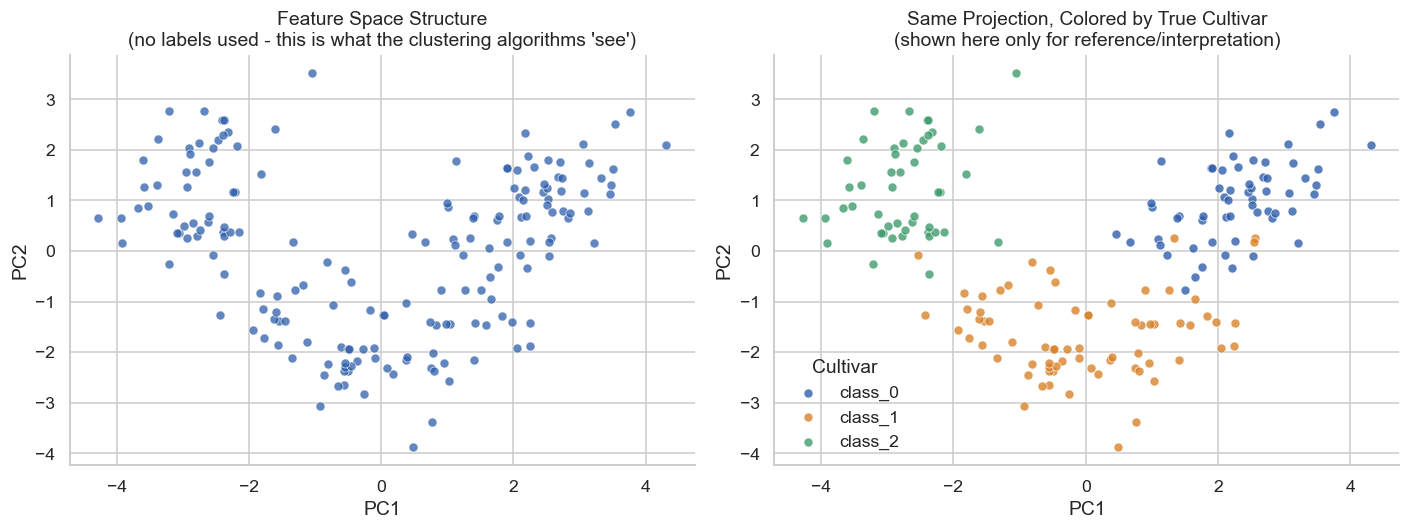

In [8]:
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca_2d.fit_transform(X)
X_pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(X_pca_df["PC1"], X_pca_df["PC2"], s=35, color=PALETTE[0], alpha=0.75,
                edgecolor="white", linewidth=0.5)
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
axes[0].set_title("Feature Space Structure\n(no labels used - this is what the clustering algorithms 'see')")

for i, name in enumerate(class_names):
    mask = y_true == i
    axes[1].scatter(X_pca_df.loc[mask, "PC1"], X_pca_df.loc[mask, "PC2"], s=35,
                     color=PALETTE[i], alpha=0.8, edgecolor="white", linewidth=0.5, label=name)
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
axes[1].set_title("Same Projection, Colored by True Cultivar\n(shown here only for reference/interpretation)")
axes[1].legend(title="Cultivar", frameon=False)

plt.tight_layout()
plt.savefig(FIGURE_DIR / "04_pca_feature_space.png", bbox_inches="tight")
plt.show()


**Interpretation.** Even before any clustering is performed, the unlabeled PCA projection in the left panel shows visible sub-structure rather than a single homogeneous cloud. The right panel uses the true cultivar labels only as descriptive context, not as an input to PCA, cluster-number selection, or model fitting. Because the first two principal components explain only part of the total variance, this 2-D view should be treated as an incomplete visualization of the full 13-dimensional feature space rather than as the space on which the models are fitted.

## 5. Task (b): K-Means Clustering

### Objective Function

K-Means partitions the $N$ observations into $K$ clusters $\{C_1, \dots, C_K\}$ by minimizing the within-cluster sum of squared distances to the cluster centroids $\mu_j$:

$$
J = \sum_{j=1}^{K} \sum_{x_i \in C_j} \lVert x_i - \mu_j \rVert^2
$$

The algorithm alternates between two steps until convergence:

1. **Assignment step:** assign each point to the nearest centroid.
2. **Update step:** recompute each centroid as the mean of the points assigned to it.

K-Means favors clusters that are roughly spherical, similarly sized, and separated in Euclidean distance. This is closely related to Lloyd's iterative K-Means procedure (Lloyd, 1982).

### Choosing K: Elbow Method and Silhouette Analysis

I do not set $K$ from the known cultivar labels. Instead, the elbow method and silhouette analysis are used as label-free diagnostics to select the number of clusters.

C:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, 

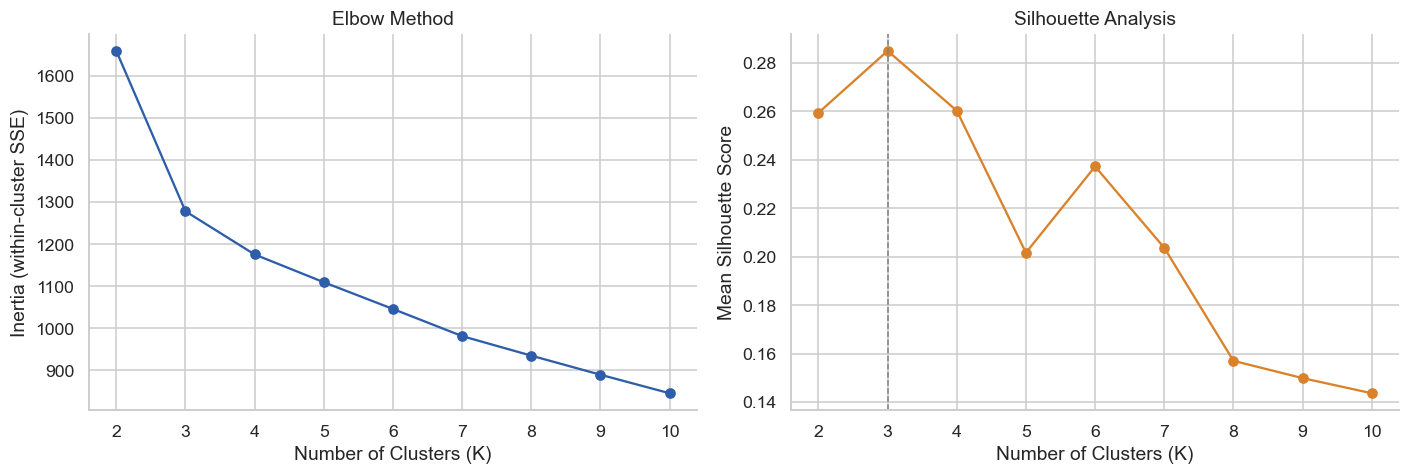

K selected by silhouette analysis: 3


In [9]:
K_range = range(2, 11)
inertias = []
sil_scores_kmeans = []

for k in K_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels_k = km.fit_predict(X)
    inertias.append(km.inertia_)
    sil_scores_kmeans.append(silhouette_score(X, labels_k))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(list(K_range), inertias, marker="o", color=PALETTE[0])
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia (within-cluster SSE)")
axes[0].set_title("Elbow Method")

axes[1].plot(list(K_range), sil_scores_kmeans, marker="o", color=PALETTE[1])
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Mean Silhouette Score")
axes[1].set_title("Silhouette Analysis")
best_k = list(K_range)[int(np.argmax(sil_scores_kmeans))]
axes[1].axvline(best_k, color="gray", linestyle="--", linewidth=1)

plt.tight_layout()
plt.savefig(FIGURE_DIR / "05_kmeans_k_selection.png", bbox_inches="tight")
plt.show()

print(f"K selected by silhouette analysis: {best_k}")
results["kmeans_k_selected"] = int(best_k)
results["kmeans_silhouette_by_k"] = {int(k): float(s) for k, s in zip(K_range, sil_scores_kmeans)}


**Justification of K.** The silhouette score reaches its maximum at $K=3$ among all tested values from $K=2$ to $K=10$. The elbow curve also shows a noticeable reduction in the rate of improvement beyond approximately $K=3$. I therefore use $K=3$ for the final models. Importantly, the true cultivar labels do not enter either the inertia calculation or the silhouette calculation used to make this choice.

C:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


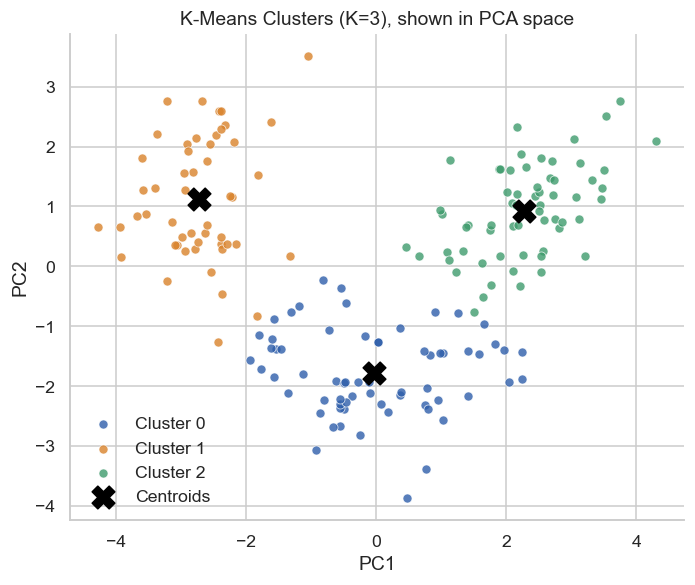

Silhouette score (K-Means, K=3): 0.285


In [10]:
K_FINAL = best_k
kmeans_final = KMeans(n_clusters=K_FINAL, n_init=10, random_state=RANDOM_STATE)
labels_kmeans = kmeans_final.fit_predict(X)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for c in range(K_FINAL):
    mask = labels_kmeans == c
    ax.scatter(X_pca_df.loc[mask, "PC1"], X_pca_df.loc[mask, "PC2"], s=35, color=PALETTE[c],
               alpha=0.8, edgecolor="white", linewidth=0.5, label=f"Cluster {c}")
centers_pca = pca_2d.transform(pd.DataFrame(kmeans_final.cluster_centers_, columns=X.columns))
ax.scatter(centers_pca[:, 0], centers_pca[:, 1], s=220, marker="X", color="black",
           label="Centroids", zorder=5)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title(f"K-Means Clusters (K={K_FINAL}), shown in PCA space")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "06_kmeans_clusters.png", bbox_inches="tight")
plt.show()

sil_kmeans_final = silhouette_score(X, labels_kmeans)
print(f"Silhouette score (K-Means, K={K_FINAL}): {sil_kmeans_final:.3f}")
results["kmeans_silhouette_final"] = float(sil_kmeans_final)


## 6. Task (c): Hierarchical (Agglomerative) Clustering

Agglomerative clustering starts with every observation as its own cluster and iteratively merges the two closest clusters until one cluster remains. A **linkage** rule defines the distance between clusters:

- **Single linkage:** minimum pairwise distance between clusters, which can produce elongated chains.
- **Complete linkage:** maximum pairwise distance, which tends to produce compact clusters.
- **Average linkage:** mean pairwise distance.
- **Ward linkage:** merges the pair of clusters that produces the smallest increase in total within-cluster variance.

I compare linkage strategies using the **cophenetic correlation coefficient**, which measures how faithfully the dendrogram preserves the original pairwise distances.

In [11]:
linkage_methods = ["single", "complete", "average", "ward"]
coph_corrs = {}
Z_dict = {}

pairwise_dist = pdist(X, metric="euclidean")

for method in linkage_methods:
    Z = linkage(X, method=method, metric="euclidean")
    Z_dict[method] = Z
    c, _ = cophenet(Z, pairwise_dist)
    coph_corrs[method] = c

for method, c in coph_corrs.items():
    print(f"{method:>10s} linkage -> cophenetic correlation = {c:.3f}")

results["linkage_cophenetic_corr"] = {k: float(v) for k, v in coph_corrs.items()}
best_linkage = max(coph_corrs, key=coph_corrs.get)
print(f"\nLinkage with highest cophenetic correlation: {best_linkage}")


    single linkage -> cophenetic correlation = 0.544
  complete linkage -> cophenetic correlation = 0.592
   average linkage -> cophenetic correlation = 0.759
      ward linkage -> cophenetic correlation = 0.662

Linkage with highest cophenetic correlation: average


Average linkage produces the highest cophenetic correlation in this dataset, so it best preserves the original pairwise distances according to that diagnostic. For the **final controlled comparison**, however, I use **Ward linkage**. Ward's method minimizes increases in within-cluster variance, making its objective closely related to the variance criterion used by K-Means (Ward, 1963). Ward is therefore selected for methodological comparability with K-Means, not because it has the largest cophenetic coefficient.

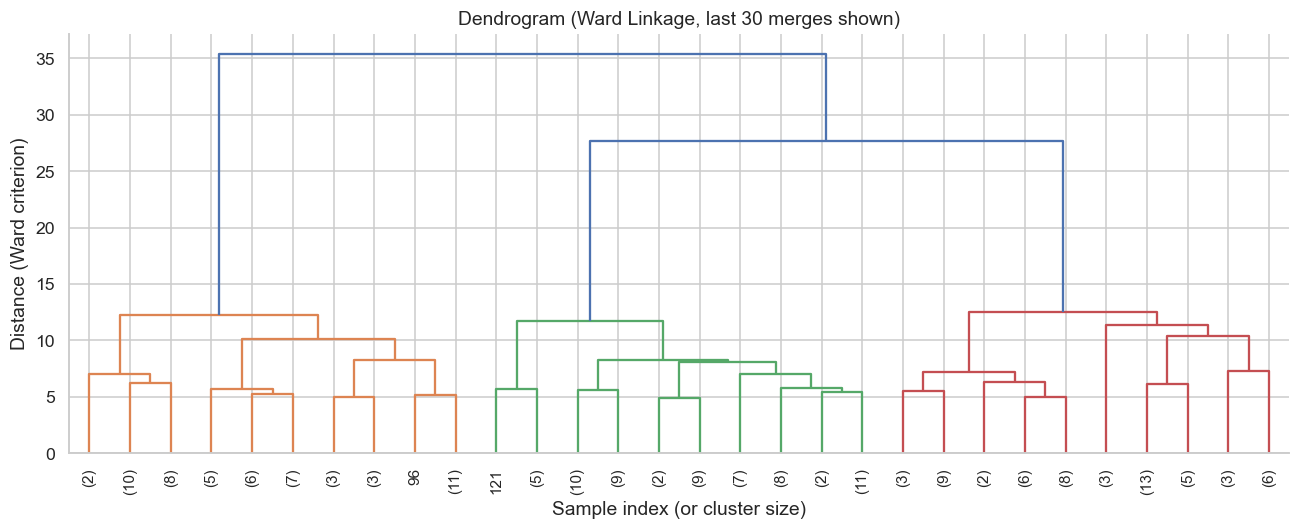

In [12]:
fig, ax = plt.subplots(figsize=(12, 5))
dendrogram(Z_dict["ward"], truncate_mode="lastp", p=30, leaf_rotation=90,
           color_threshold=0.7 * max(Z_dict["ward"][:, 2]), ax=ax)
ax.set_title("Dendrogram (Ward Linkage, last 30 merges shown)")
ax.set_xlabel("Sample index (or cluster size)")
ax.set_ylabel("Distance (Ward criterion)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "07_dendrogram.png", bbox_inches="tight")
plt.show()


**Interpreting the dendrogram.** Each horizontal merge represents two clusters being joined at the height shown on the y-axis. Cutting the dendrogram at a chosen height produces a specific number of clusters. The Ward dendrogram shows three prominent branches that remain separate until comparatively larger merge heights near the top, which is consistent with a three-group solution. I cut the dendrogram at three clusters so that hierarchical clustering, K-Means, and GMM can be compared under the same value of $K$.

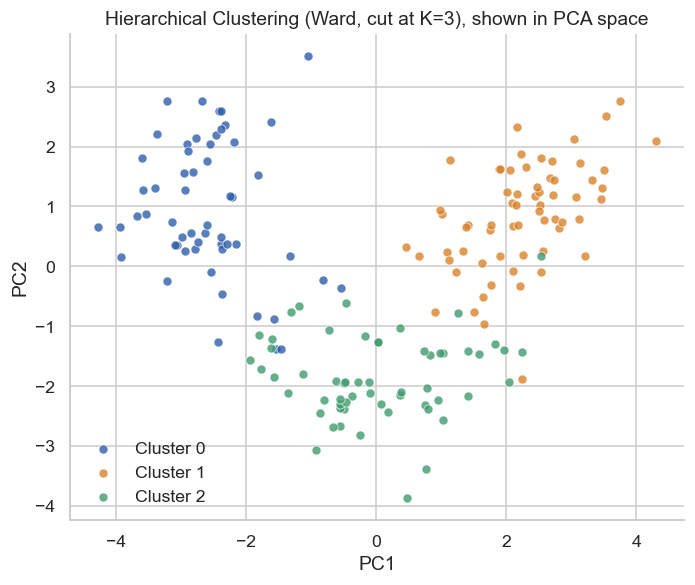

Silhouette score (Hierarchical, Ward, K=3): 0.277


In [13]:
labels_hier = fcluster(Z_dict["ward"], t=K_FINAL, criterion="maxclust") - 1  # zero-index

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for c in range(K_FINAL):
    mask = labels_hier == c
    ax.scatter(X_pca_df.loc[mask, "PC1"], X_pca_df.loc[mask, "PC2"], s=35, color=PALETTE[c],
               alpha=0.8, edgecolor="white", linewidth=0.5, label=f"Cluster {c}")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title(f"Hierarchical Clustering (Ward, cut at K={K_FINAL}), shown in PCA space")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "08_hierarchical_clusters.png", bbox_inches="tight")
plt.show()

sil_hier_final = silhouette_score(X, labels_hier)
print(f"Silhouette score (Hierarchical, Ward, K={K_FINAL}): {sil_hier_final:.3f}")
results["hierarchical_silhouette_final"] = float(sil_hier_final)


## 7. Task (d): Gaussian Mixture Model (Expectation-Maximization)

A **Gaussian Mixture Model** assumes the data is generated from a weighted mixture of $K$ multivariate Gaussian components:

$$
p(x) = \sum_{j=1}^{K} \pi_j \, \mathcal{N}(x \mid \mu_j, \Sigma_j)
$$

Because component memberships are unobserved latent variables, the parameters $\{\pi_j, \mu_j, \Sigma_j\}$ are estimated using the **Expectation-Maximization (EM)** algorithm (Dempster, Laird, & Rubin, 1977), which alternates between two steps:

- **E-step (Expectation):** given the current parameters, compute the posterior probability, or responsibility, that each point $x_i$ belongs to each component $j$:
  $$
  \gamma_{ij} = P(z_i = j \mid x_i) = \frac{\pi_j \mathcal{N}(x_i \mid \mu_j, \Sigma_j)}
  {\sum_{k=1}^{K} \pi_k \mathcal{N}(x_i \mid \mu_k, \Sigma_k)}
  $$
- **M-step (Maximization):** re-estimate $\pi_j$, $\mu_j$, and $\Sigma_j$ using the responsibilities $\gamma_{ij}$ as soft weights, maximizing the expected complete-data log-likelihood.

These two steps repeat until the likelihood converges.

### Hard vs. Soft Assignment

K-Means makes a **hard assignment**, meaning each point receives one cluster label. GMM instead produces a **soft assignment**, meaning each point has a full probability distribution $(\gamma_{i1}, \dots, \gamma_{iK})$ over the components. This allows GMM to quantify uncertainty when observations do not belong overwhelmingly to a single component.

In [14]:
gmm_final = GaussianMixture(n_components=K_FINAL, covariance_type="full",
                            random_state=RANDOM_STATE, n_init=10)
gmm_final.fit(X)
labels_gmm = gmm_final.predict(X)
probs_gmm = gmm_final.predict_proba(X)

print(f"GMM converged: {gmm_final.converged_} after {gmm_final.n_iter_} EM iterations")
results["gmm_converged"] = bool(gmm_final.converged_)
results["gmm_n_iter"] = int(gmm_final.n_iter_)

# Show the five observations with the highest assignment entropy.
entropy = -(probs_gmm * np.log(probs_gmm + 1e-12)).sum(axis=1)
uncertain_idx = np.argsort(entropy)[::-1][:5]
soft_table = pd.DataFrame(probs_gmm[uncertain_idx], columns=[f"P(cluster {c})" for c in range(K_FINAL)])
soft_table.insert(0, "sample_index", uncertain_idx)
soft_table.insert(1, "hard_label (argmax)", labels_gmm[uncertain_idx])
print("Five samples with the most uncertain (highest-entropy) soft assignments:")
soft_table.round(3)

GMM converged: True after 2 EM iterations
Five samples with the most uncertain (highest-entropy) soft assignments:


C:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, 

,sample_index,hard_label (argmax),P(cluster 0),P(cluster 1),P(cluster 2)
0,81,1,0.361,0.639,0.00
1,43,0,0.963,0.037,0.00
2,117,1,0.030,0.970,0.00
3,118,2,0.000,0.030,0.97
4,65,1,0.013,0.987,0.00


The five highest-entropy assignments show that uncertainty is limited in this dataset. The most ambiguous observation, sample 81, has posterior probabilities of approximately 0.639 and 0.361 for two components. The other four observations still have maximum posterior probabilities above 0.96. Even though most assignments are confident here, GMM retains an important advantage over K-Means and hierarchical clustering: it can quantify membership uncertainty instead of returning only a hard cluster label.

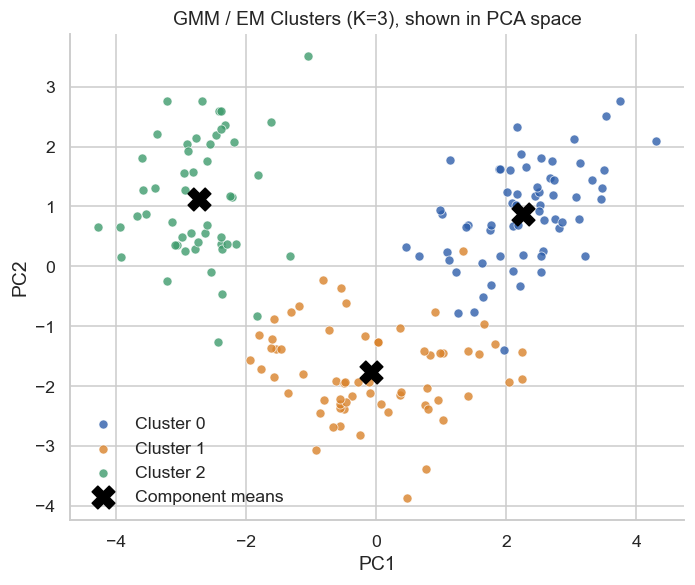

Silhouette score (GMM, K=3): 0.284
Final log-likelihood: -2089.60
BIC: 5806.29  |  AIC: 4807.21


In [15]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for c in range(K_FINAL):
    mask = labels_gmm == c
    ax.scatter(X_pca_df.loc[mask, "PC1"], X_pca_df.loc[mask, "PC2"], s=35, color=PALETTE[c],
               alpha=0.8, edgecolor="white", linewidth=0.5, label=f"Cluster {c}")
means_pca = pca_2d.transform(pd.DataFrame(gmm_final.means_, columns=X.columns))
ax.scatter(means_pca[:, 0], means_pca[:, 1], s=220, marker="X", color="black",
           label="Component means", zorder=5)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
ax.set_title(f"GMM / EM Clusters (K={K_FINAL}), shown in PCA space")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "09_gmm_clusters.png", bbox_inches="tight")
plt.show()

sil_gmm_final = silhouette_score(X, labels_gmm)
print(f"Silhouette score (GMM, K={K_FINAL}): {sil_gmm_final:.3f}")
print(f"Final log-likelihood: {gmm_final.score(X)*len(X):.2f}")
print(f"BIC: {gmm_final.bic(X):.2f}  |  AIC: {gmm_final.aic(X):.2f}")
results["gmm_silhouette_final"] = float(sil_gmm_final)
results["gmm_bic"] = float(gmm_final.bic(X))
results["gmm_aic"] = float(gmm_final.aic(X))


## 8. Task (e): Experimental Comparison

I compare the three clustering solutions using:

- **Silhouette Score** (internal measure, no labels needed): evaluates cohesion and separation using only the geometry of the standardized feature space.
- **Adjusted Rand Index (ARI)** (external measure): evaluates agreement between the discovered clusters and the known cultivar labels. The labels are used here for final external validation and in earlier descriptive plots only; they are never used in PCA fitting, cluster-number selection, or clustering model fitting.

In [16]:
cluster_solutions = {
    "K-Means": labels_kmeans,
    "Hierarchical (Ward)": labels_hier,
    "GMM / EM": labels_gmm,
}

comparison_rows = []
for name, labels in cluster_solutions.items():
    sil = silhouette_score(X, labels)
    ari = adjusted_rand_score(y_true, labels)
    comparison_rows.append({"Method": name, "Silhouette Score": round(sil, 3),
                             "Adjusted Rand Index": round(ari, 3)})

comparison_df = pd.DataFrame(comparison_rows).set_index("Method")
results["comparison_table"] = comparison_df.reset_index().to_dict(orient="records")
comparison_df


,Silhouette Score,Adjusted Rand Index
Method,,
K-Means,0.285,0.897
Hierarchical (Ward),0.277,0.790
GMM / EM,0.284,0.880


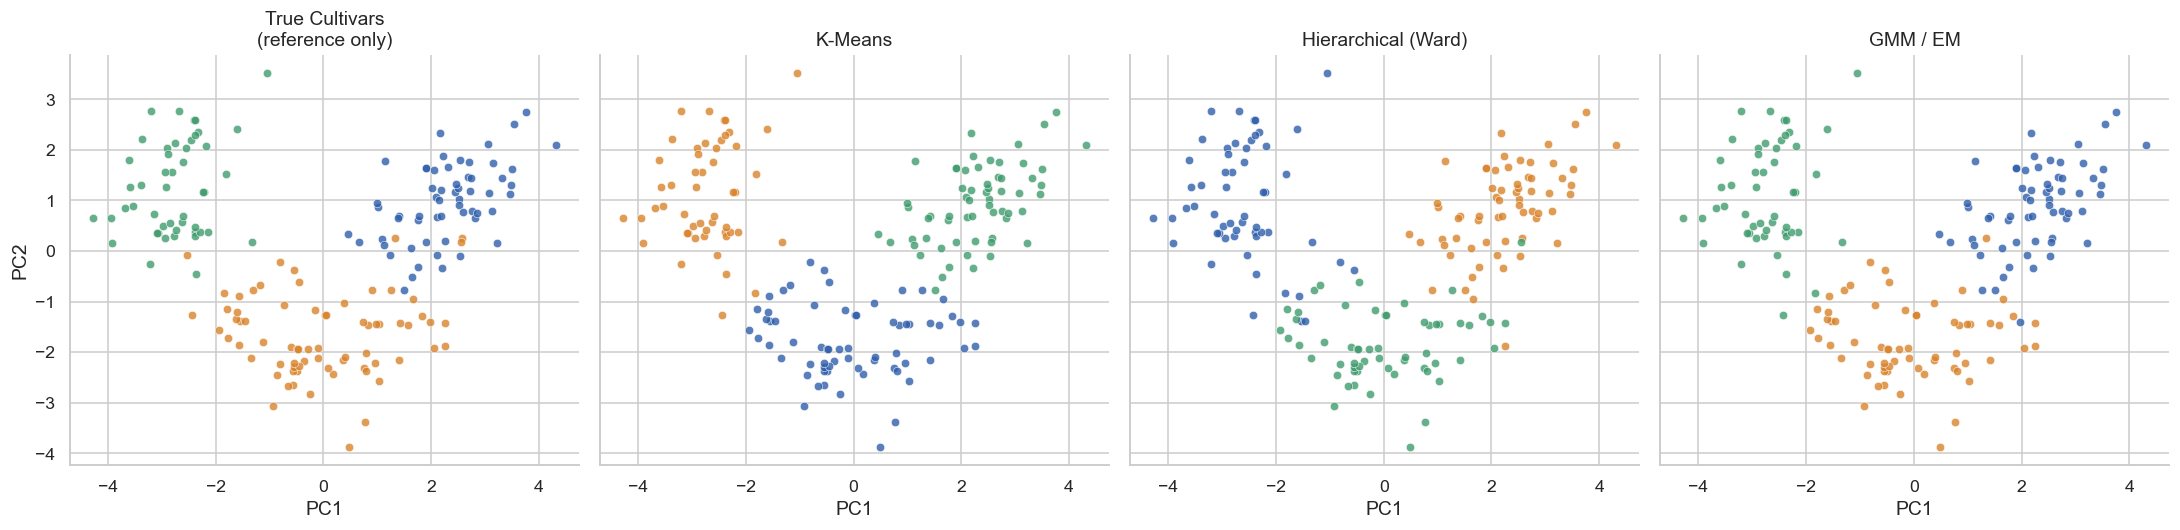

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharex=True, sharey=True)

titles = ["True Cultivars\n(reference only)", "K-Means", "Hierarchical (Ward)", "GMM / EM"]
label_sets = [y_true.values, labels_kmeans, labels_hier, labels_gmm]

for ax, title, labels in zip(axes, titles, label_sets):
    for c in np.unique(labels):
        mask = labels == c
        ax.scatter(X_pca_df.loc[mask, "PC1"], X_pca_df.loc[mask, "PC2"], s=30,
                   color=PALETTE[c % len(PALETTE)], alpha=0.8, edgecolor="white", linewidth=0.4)
    ax.set_title(title)
    ax.set_xlabel("PC1")
axes[0].set_ylabel("PC2")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "10_comparison_2d.png", bbox_inches="tight")
plt.show()


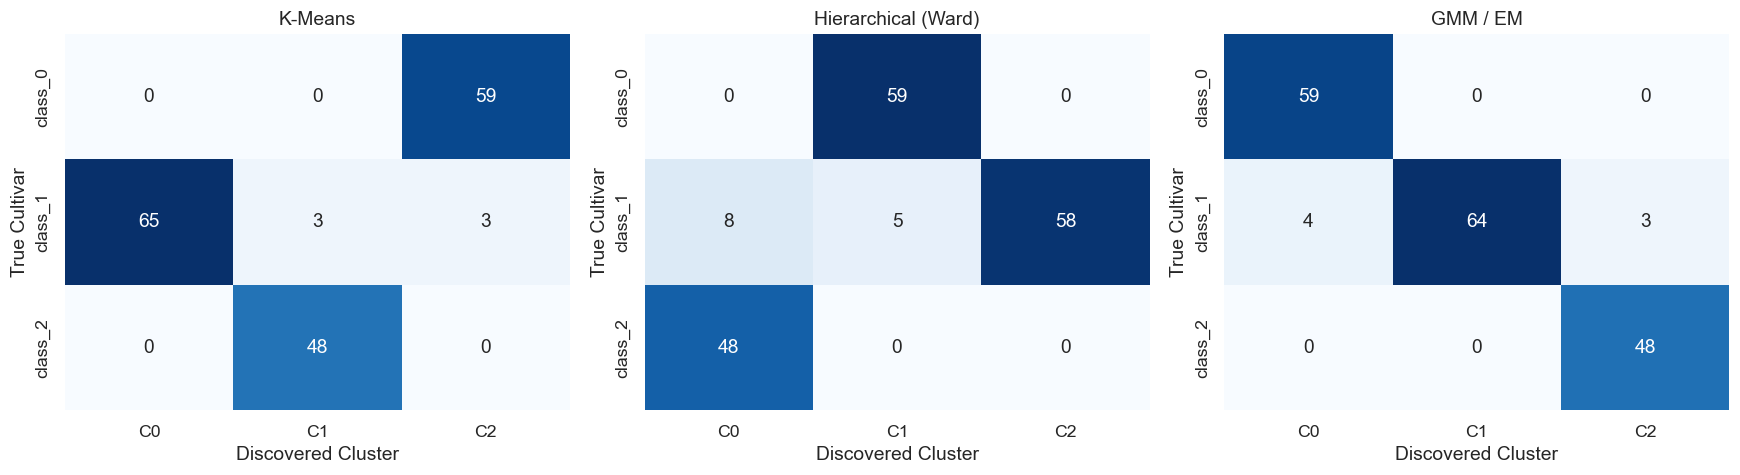

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, labels) in zip(axes, cluster_solutions.items()):
    cm = confusion_matrix(y_true, labels)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=[f"C{c}" for c in range(cm.shape[1])],
                yticklabels=class_names)
    ax.set_title(name)
    ax.set_xlabel("Discovered Cluster")
    ax.set_ylabel("True Cultivar")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "11_confusion_matrices.png", bbox_inches="tight")
plt.show()


**Note on the confusion matrices.** Cluster indices are arbitrary. For example, cluster "0" from K-Means has no inherent relationship to cluster "0" from GMM. The matrices should therefore be interpreted through row and column concentration, asking whether each true cultivar maps predominantly to a single discovered cluster, rather than through the numerical alignment of cluster indices on the diagonal.

## 9. Discussion, Limitations, and Answer to the Research Question

**How does the underlying geometry and probability distribution of the dataset affect the clusters discovered by each method?**

- **K-Means** favors convex, compact, and roughly isotropic clusters in standardized Euclidean space because it minimizes squared distance to a single centroid. On this dataset it achieves the highest ARI, suggesting that the dominant cultivar structure is reasonably compatible with a centroid-based partition.
- **Hierarchical clustering (Ward linkage)** uses a related variance criterion but constructs the partition through greedy, irreversible merges rather than iterative point relocation. This produces a deterministic dendrogram and exposes nested structure, but early merges cannot later be reversed. Its lower ARI here reflects a less clean isolation of one cultivar than under K-Means or GMM.
- **GMM/EM** allows each component to have its own full covariance matrix, so it can represent elliptical components with different orientations. It also provides posterior membership probabilities rather than only hard labels. In this dataset the highest-entropy cases are mostly still assigned with high confidence, so the practical uncertainty is limited, but the model retains the ability to express it.

**Practical outcome on this dataset.** All three methods recover a clustering that agrees strongly with the three known cultivars under ARI. Their silhouette scores are all close to 0.28, however, which indicates only moderate internal geometric separation rather than exceptionally distinct clusters. The combination of strong external agreement and modest silhouette values is not contradictory because ARI and silhouette measure different properties. Overall, the standardized Wine data contain a compact, structured partition that all three methods can recover, while differences in their objectives and assignment rules affect the treatment of borderline observations.

**Limitations.**

1. **Sample size relative to model complexity.** With 13 features, each full Gaussian component requires 13 mean parameters and $13\times14/2=91$ unique covariance parameters, giving 104 mean/covariance parameters per component. With three components this gives 312 such parameters, plus two independent mixture-weight parameters, for 314 free mixture parameters in total. This is substantial relative to only 178 observations, so the covariance estimates should be interpreted cautiously.
2. **Choice of K.** The elbow and silhouette analyses support $K=3$, but both are heuristic diagnostics; neither proves that three is the true number of generative processes.
3. **Linkage and covariance sensitivity.** Average linkage gives the highest cophenetic correlation, while Ward is chosen for the final comparison because its variance objective is closely related to K-Means. A different linkage could produce a different hierarchy. Likewise, the GMM result depends on covariance structure; `full` covariance is used here, while `diagonal` or `tied` structures would trade flexibility for fewer parameters.
4. **Standardization choice.** Z-score standardization treats every chemical feature as equally important a priori. Domain knowledge or a formal feature-selection step could justify a different weighting of measurements.
5. **External validation caveat.** ARI is available only because the benchmark dataset includes ground-truth labels. In a genuine unsupervised deployment such labels may not exist, so cluster quality would need to be judged through internal measures, stability checks, and domain interpretation.

In [19]:
with open(RESULT_PATH, "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2)
print(f"Saved results summary to: {RESULT_PATH.name}")
print(json.dumps(results, indent=2))

Saved results summary to: results_summary.json
{
  "pca_n_components_90pct": 8,
  "pca_variance_2pc": 0.5540633835693526,
  "kmeans_k_selected": 3,
  "kmeans_silhouette_by_k": {
    "2": 0.2593169555318255,
    "3": 0.2848589191898987,
    "4": 0.26017035223704527,
    "5": 0.20161908294074093,
    "6": 0.23716725754166545,
    "7": 0.2036275812271175,
    "8": 0.1570139556393107,
    "9": 0.14988199178183517,
    "10": 0.1436384079124149
  },
  "kmeans_silhouette_final": 0.2848589191898987,
  "linkage_cophenetic_corr": {
    "single": 0.543623119924762,
    "complete": 0.5916829459078577,
    "average": 0.7590840545998375,
    "ward": 0.6623487206613264
  },
  "hierarchical_silhouette_final": 0.2774439826952266,
  "gmm_converged": true,
  "gmm_n_iter": 2,
  "gmm_silhouette_final": 0.2844212860533542,
  "gmm_bic": 5806.2851211775405,
  "gmm_aic": 4807.205086385826,
  "comparison_table": [
    {
      "Method": "K-Means",
      "Silhouette Score": 0.285,
      "Adjusted Rand Index": 0.8

## References

- Aeberhard, S., & Forina, M. (1992). *Wine* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5PC7J
- Dempster, A. P., Laird, N. M., & Rubin, D. B. (1977). Maximum likelihood from incomplete data via the EM algorithm. *Journal of the Royal Statistical Society, Series B, 39*(1), 1-38.
- Hotelling, H. (1933). Analysis of a complex of statistical variables into principal components. *Journal of Educational Psychology, 24*(6), 417-441.
- Lloyd, S. (1982). Least squares quantization in PCM. *IEEE Transactions on Information Theory, 28*(2), 129-137.
- Pearson, K. (1901). On lines and planes of closest fit to systems of points in space. *Philosophical Magazine, 2*(11), 559-572.
- Ward, J. H. (1963). Hierarchical grouping to optimize an objective function. *Journal of the American Statistical Association, 58*(301), 236-244.
- Pedregosa, F., et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.